# Fitting Eddy Currents with Using Inverse Laplace

Using inverse laplace and curvefit, we will fit the data gathered from the NMR probe (stored in the 'data' folder) to get the decay parameters.


N_tau: Number of taus that can be identified

tau_min: Minimum tau value available

tau_max: Maximum tau value available

lam: regularisation of the inverse laplace transform for the tau peaks over tau_min and tau_max.

N_exp_max: Max number of tau's used in the fitting (needs to be less than the globalised MAX_EXP value stored in 'globals/fitting_pars')



### Imports

In [1]:
from matipo import SEQUENCE_DIR, GLOBALS_DIR
import pandas as pd

In [2]:
from user_interface.fitting import Fit
fit = Fit()

Found: C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\data


### Load Data

In [8]:
probe_axis = "X"
gradient = "X"

df_, seq_par, g_hzpm = fit.get_data(probe_axis, gradient)

Scan parameters for loaded sequence:
{'offsets': [0, 0, 0, 0], 'a_pulse': 0.45, 't_pulse': 2.9999999999999997e-05, 't_dw': 1e-05, 'n_samples': 100, 'g_read': array([0.1, 0. , 0. ]), 'rx_chan_list': (3, 0, 1), 'pre_emphasis': False, 'b0': False, 'protocols': 'start_up_setting.txt', 'protocol_name': '', 'probe_axis': 'X', 'n_scans': 10, 'flip_angle': 4.5, 'n_pulses': 30, 'apodisation': 100, 't_acq_delay': 9.999999999999999e-05, 't_grad': 10.0, 't_ramp': 0.00025, 't_wait': 0.008, 't_end': 10.0, 't_next': 5, 'select_g': 'X', 'g_val': 0.1, 'tx_chan': 0, 'scan_type': 'measure_ec'}


### Gradient Fitting

N_tau: 1000, lam: 0.01, tau_min: 0.0001, tau_max: 10, N_exp_max: 3, type_: E, MAX_EXP: 4
E: x.max=0.001784553051270342
E: n_peaks=3
fit_A guess: [0.07340793 0.04803599 0.0355004 ]
fit_tau guess: [0.22822245 0.04005001 0.00605037]
df_fitE: 
Parameter    df_fit
       A0 -0.002202
       A1  0.062856
     tau1  0.272118
       A2  0.056673
     tau2  0.053684
       A3  0.037123
     tau3  0.006896
       A4  0.000000
     tau4  0.000000


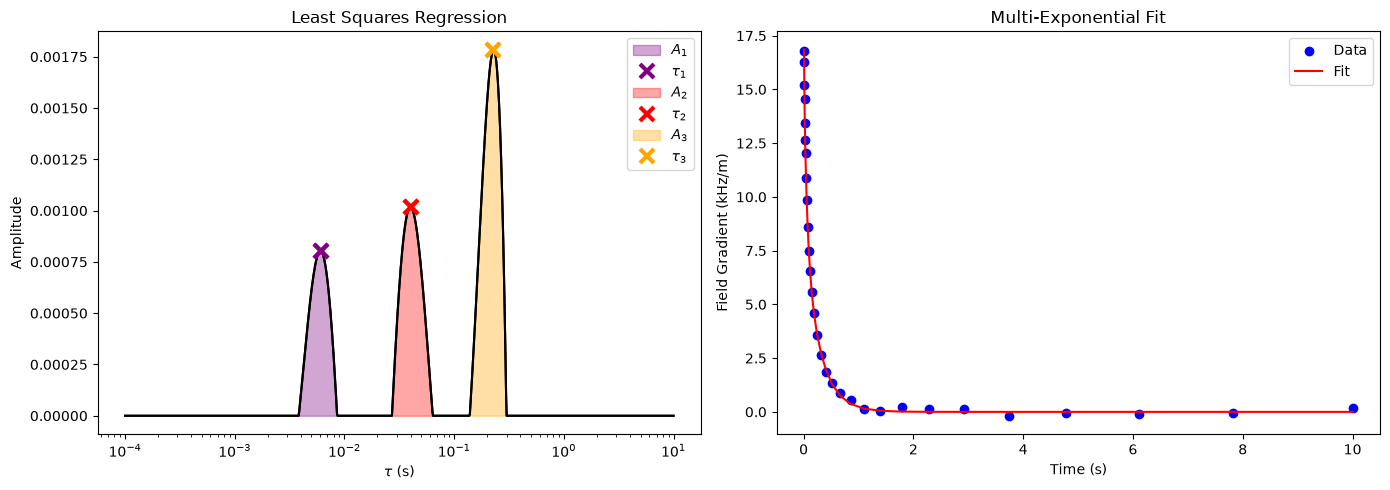

Maximum residuals variation: 524.75Hz/m
Std Dev of difference: 123.16Hz/m


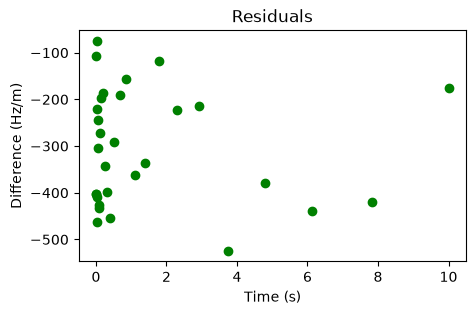

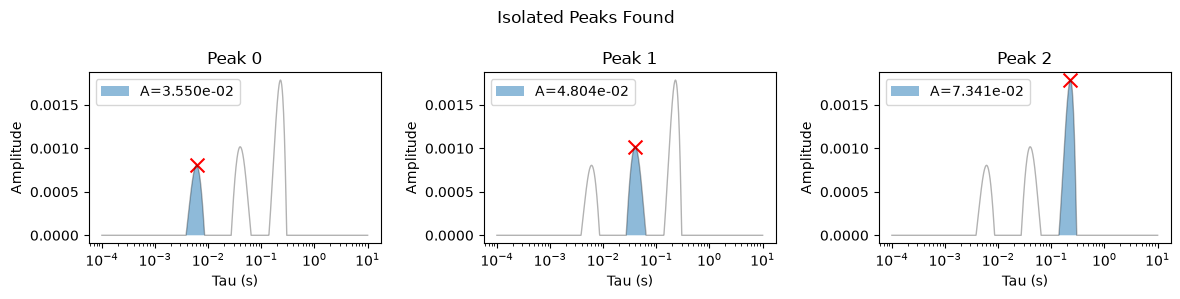

In [9]:
N_tau = 1000
lam = 1e-2
tau_min = 1e-4
tau_max = 10
N_exp_max = 3

df_fitE, fitted_values, taus, x, props, pk, fit_params = fit.fit_inv(N_tau, 
                                                                   lam, 
                                                                   tau_min, 
                                                                   tau_max, 
                                                                   df_["E(t)"], 
                                                                   df_["times (s)"],
                                                                   N_exp_max, 
                                                                   type_ = "E")

fit.plot_fit(df_, taus, x, fitted_values, props, pk, N_exp_max, type_ = "E")
var = fit.plot_residuals(df_, fitted_values, type_ = "E")
fit.plot_isolated_peaks(props, pk, x, taus)

### Save Gradient df

In [5]:
fit.save_fit(df_fitE, type_ = "E")

Saved df to C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\data\Measure_EC\Zgrad_Zeddy/df_fitE.csv


### Offset Fitting

N_tau: 1000, lam: 0.001, tau_min: 0.0001, tau_max: 100, N_exp_max: 4, type_: B0, MAX_EXP: 4
B0: x.max=4.781600873429745e-05
B0: n_peaks=12
fit_A guess: [-0.00306633  0.00167092 -0.00115918 -0.00105759]
fit_tau guess: [0.0022457  0.00507815 0.01071593 0.22769703]
df_fitB0: 
Parameter    df_fit
       A0 -0.000709
       A1 -0.945338
     tau1  0.000705
       A2 -0.000655
     tau2  0.027704
       A3 -0.000376
     tau3  0.147017
       A4 -0.000312
     tau4  1.806801


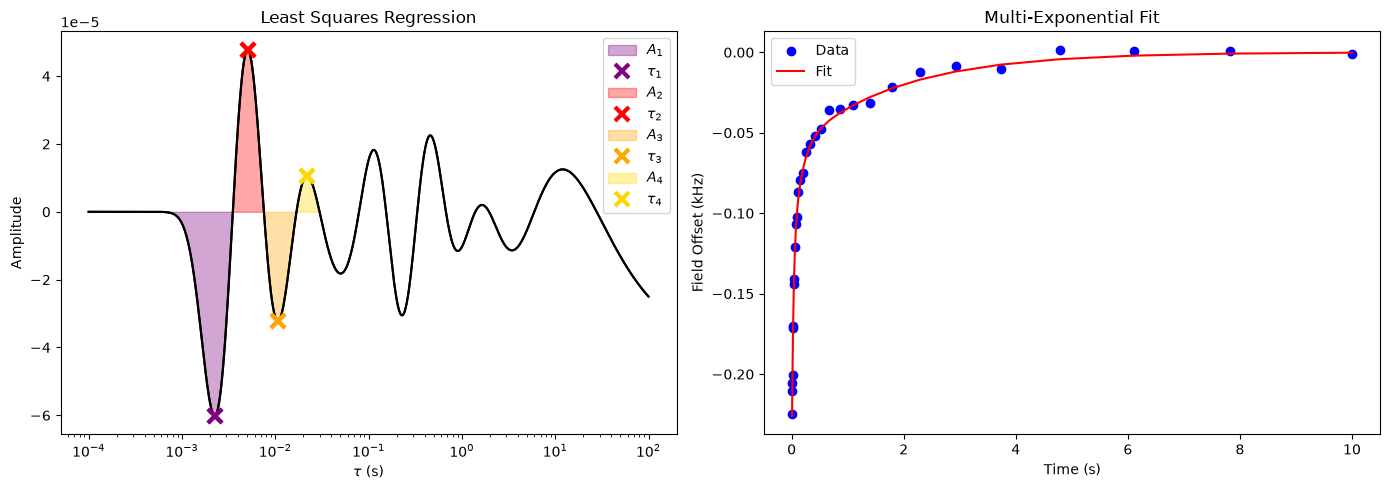

Maximum residuals variation: 145.02Hz
Std Dev of difference: 4.52Hz


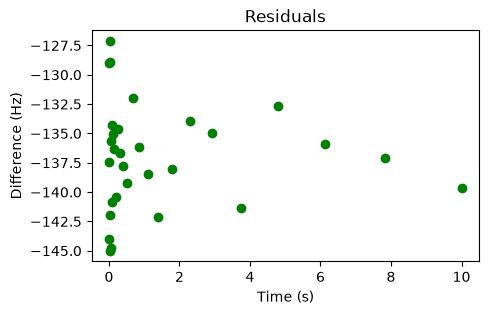

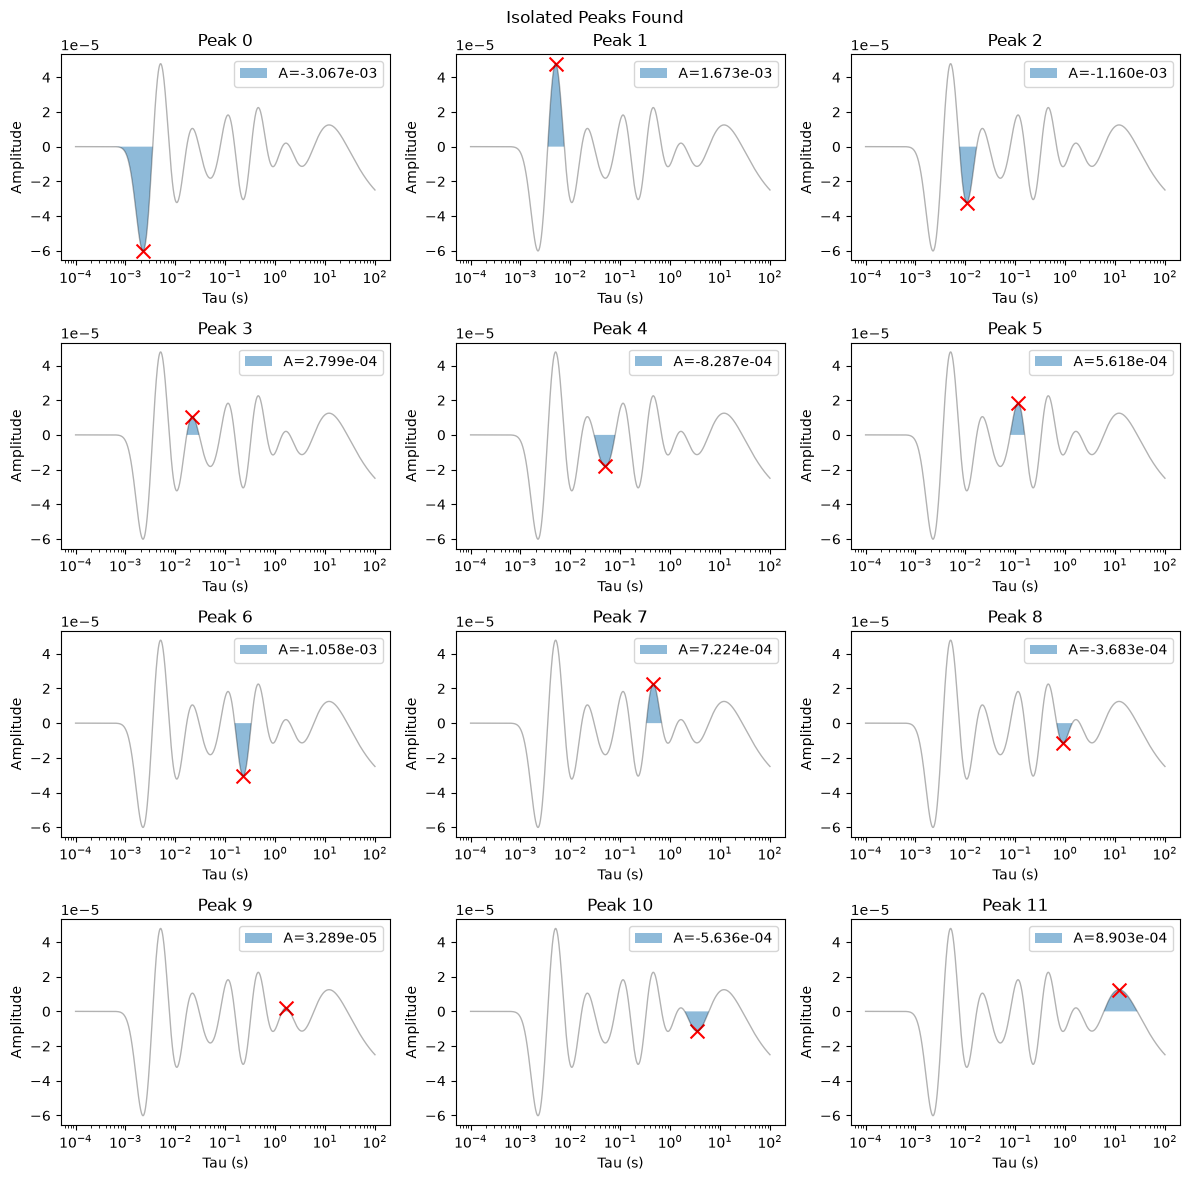

In [6]:
N_tau = 1000
lam = 1e-3
tau_min = 1e-4
tau_max = 100
N_exp_max = 4

df_fitB0, fitted_values, taus, x, props, pk, fit_params = fit.fit_inv(N_tau, 
                                                                   lam, 
                                                                   tau_min, 
                                                                   tau_max, 
                                                                   df_["B0(t)"], 
                                                                   df_["times (s)"],
                                                                   N_exp_max, 
                                                                   type_ = "B0")

fit.plot_fit(df_, taus, x, fitted_values, props, pk, N_exp_max, type_ = "B0")
var = fit.plot_residuals(df_, fitted_values, type_ = "B0")
fit.plot_isolated_peaks(props, pk, x, taus)

### Save Offset df

In [7]:
fit.save_fit(df_fitB0, type_ = "B0")

Saved df to C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\data\Measure_EC\Zgrad_Zeddy/df_fitB0.csv
